In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast 

In [2]:
raw_data = pd.read_csv(r'C:\Users\MAJEED\Desktop\APPS\data_jobs.csv')
raw_data.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


In [3]:
df = raw_data.copy()

In [4]:
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [5]:
df.dropna(subset = ['job_skills'], inplace = True)

In [6]:
def clean_list(skill_clean):
    return ast.literal_eval(skill_clean)

In [7]:
df['job_skills'] = df['job_skills'].apply(clean_list)

In [8]:
df_US = df[(df['job_country'] == 'United States')].dropna(subset = ['salary_year_avg'])

In [9]:
job_titles = df_US['job_title_short'].value_counts().index[:6].tolist()
job_titles

['Data Scientist',
 'Data Analyst',
 'Data Engineer',
 'Senior Data Scientist',
 'Senior Data Engineer',
 'Senior Data Analyst']

In [10]:
df_US_top6 = df_US[(df_US['job_title_short'].isin(job_titles))]

In [11]:
job_order = df_US_top6.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending = False).index

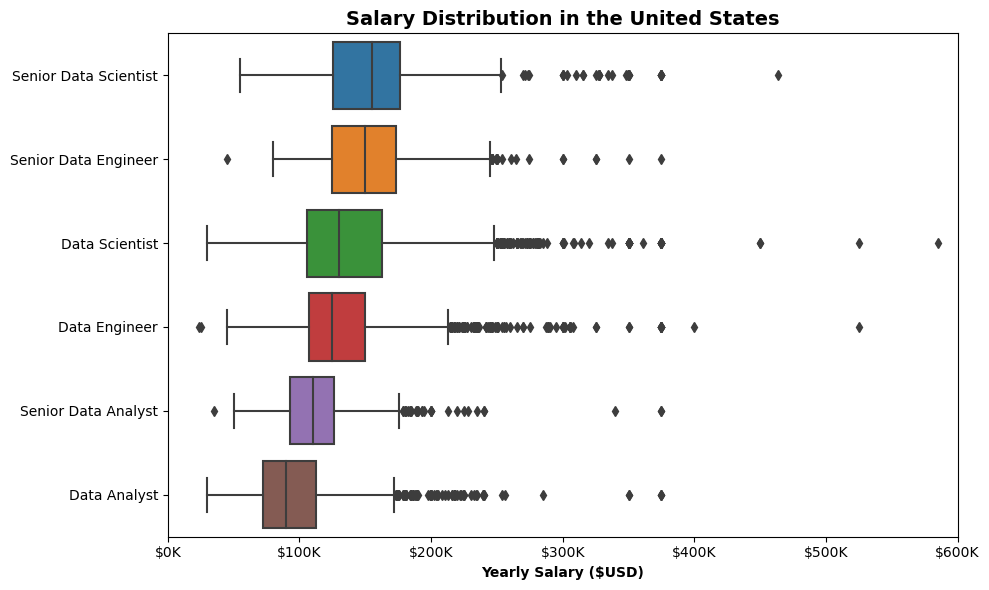

In [12]:
plt.figure(figsize = (10,6))
sns.boxplot(data = df_US_top6, x = 'salary_year_avg', y = 'job_title_short', order = job_order)
plt.title('Salary Distribution in the United States', fontsize = 14, fontweight = 'bold')
plt.xlabel('Yearly Salary ($USD)', fontweight = 'bold')
plt.xlim(0, 600000)
plt.ylabel('')

plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))

plt.tight_layout()
plt.show()

# Investigate Median Salary Vs Skill for Data Analysts

In [13]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]

df_DA_US = df_DA_US.dropna(subset = ['salary_year_avg'])

In [14]:
df_DA_US = df_DA_US.explode('job_skills')

In [15]:
df_DA_US_grouped = df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])

In [16]:
df_DA_top_pay = df_DA_US_grouped.sort_values(by = 'median', ascending = False).head(10)
df_DA_top_pay

,count,median
job_skills,,
dplyr,2,196250.0
bitbucket,3,189000.0
gitlab,3,186000.0
solidity,1,179000.0
hugging face,1,175000.0
couchbase,1,160515.0
ansible,1,159640.0
mxnet,2,149000.0
cassandra,6,148250.0


In [17]:
df_DA_skills = df_DA_US_grouped.sort_values(by = 'count', ascending = False).head(10).sort_values(by = 'median', ascending = False).head(10)
df_DA_skills

,count,median
job_skills,,
python,1431,97500.00
tableau,1364,92875.00
r,893,92500.00
sql server,286,92500.00
sql,2508,91000.00
sas,926,90000.00
power bi,838,90000.00
powerpoint,462,85000.00
excel,1808,84392.00


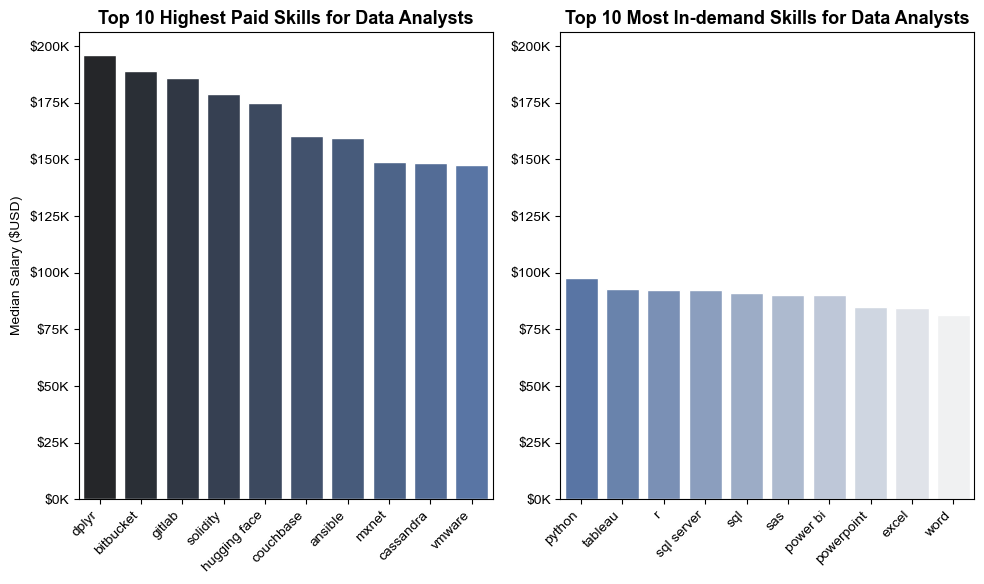

In [18]:
fig, ax = plt.subplots(1,2, figsize = (10,6))
sns.set_theme(style = 'ticks')

#Top 10 Highest Paid Skills for Data Analysts
sns.barplot(data = df_DA_top_pay, y = 'median', x = df_DA_top_pay.index, ax = ax[0], palette = 'dark:b')
ax[0].set_title('Top 10 Highest Paid Skills for Data Analysts', fontsize = 13, fontweight = 'bold')
ax[0].set_ylabel('Median Salary ($USD)')
ax[0].set_xlabel('')
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45, ha='right')
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))

#Top 10 Most In-Demand Skills for Data Analysts
sns.barplot(data = df_DA_skills, y = 'median', x = df_DA_skills.index, ax = ax[1], palette = 'light:b_r')
ax[1].set_title('Top 10 Most In-demand Skills for Data Analysts', fontsize = 13, fontweight = 'bold')
ax[1].set_ylabel('')
ax[1].set_xlabel('')
ax[1].set_ylim(ax[0].get_ylim())
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45, ha='right')
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))

plt.tight_layout()
plt.show()